# Breast Cancer Classification Using Machine Learning
### Project Name: Tanushree_BreastCancerClassification
### Student: Tanushree
### Dataset: Breast Cancer Wisconsin (Diagnostic) Dataset — UCI Machine Learning Repository

---
## 1. Introduction

Breast cancer is one of the most prevalent cancers worldwide. Early and accurate detection is critical for improving patient outcomes. This project applies supervised machine learning to classify breast tumors as **Malignant (M)** or **Benign (B)** using features extracted from digitized images of fine needle aspirate (FNA) of breast masses.

The dataset used is the **Breast Cancer Wisconsin (Diagnostic) Dataset** from the UCI Machine Learning Repository, containing 569 samples and 30 real-valued features computed from cell nucleus characteristics.

Three classification algorithms are trained and evaluated:
- Logistic Regression
- Support Vector Machine (SVM)
- Random Forest Classifier

Given the medical context, **recall for malignant cases** (minimizing false negatives) is treated as a critical evaluation criterion alongside overall accuracy.

---
## 2. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report
)

# Plot style
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

print('All libraries imported successfully.')

All libraries imported successfully.


---
## 3. Load Dataset

In [2]:
# Column names for the WDBC dataset (UCI)
columns = [
    'id', 'diagnosis',
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
    'smoothness_mean', 'compactness_mean', 'concavity_mean',
    'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se',
    'smoothness_se', 'compactness_se', 'concavity_se',
    'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst',
    'smoothness_worst', 'compactness_worst', 'concavity_worst',
    'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

df = pd.read_csv('data/wdbc.data', header=None, names=columns)
print(f'Dataset loaded successfully: {df.shape[0]} rows × {df.shape[1]} columns')
df.head()

Dataset loaded successfully: 569 rows × 32 columns


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


---
## 4. Dataset Overview

In [3]:
print('=== Dataset Shape ===')
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')
print()
print('=== Column Names ===')
print(df.columns.tolist())

=== Dataset Shape ===
Rows: 569, Columns: 32

=== Column Names ===
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']


In [4]:
print('=== Data Types ===')
print(df.dtypes)

=== Data Types ===
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave_points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave_points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
c

In [5]:
print('=== Basic Info ===')
df.info()

=== Basic Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimet

In [6]:
print('=== Descriptive Statistics ===')
df.describe().T

=== Descriptive Statistics ===


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave_points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [7]:
print('=== Target Variable Distribution ===')
print(df['diagnosis'].value_counts())
print()
print('Percentage Distribution:')
print(df['diagnosis'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

=== Target Variable Distribution ===
diagnosis
B    357
M    212
Name: count, dtype: int64

Percentage Distribution:
diagnosis
B    62.74%
M    37.26%
Name: proportion, dtype: object


---
## 5. Data Cleaning

In [8]:
# Check for missing values
print('=== Missing Values ===')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'No missing values found.')

=== Missing Values ===
No missing values found.


In [9]:
# Check for duplicate rows
print('=== Duplicate Rows ===')
dupes = df.duplicated().sum()
print(f'Number of duplicate rows: {dupes}')
if dupes > 0:
    df = df.drop_duplicates()
    print(f'Duplicates removed. New shape: {df.shape}')

=== Duplicate Rows ===


Number of duplicate rows: 0


In [10]:
# Drop the 'id' column — not a predictive feature
df = df.drop(columns=['id'])
print(f'"id" column dropped. Remaining shape: {df.shape}')

"id" column dropped. Remaining shape: (569, 31)


---
## 6. Exploratory Data Analysis (EDA)

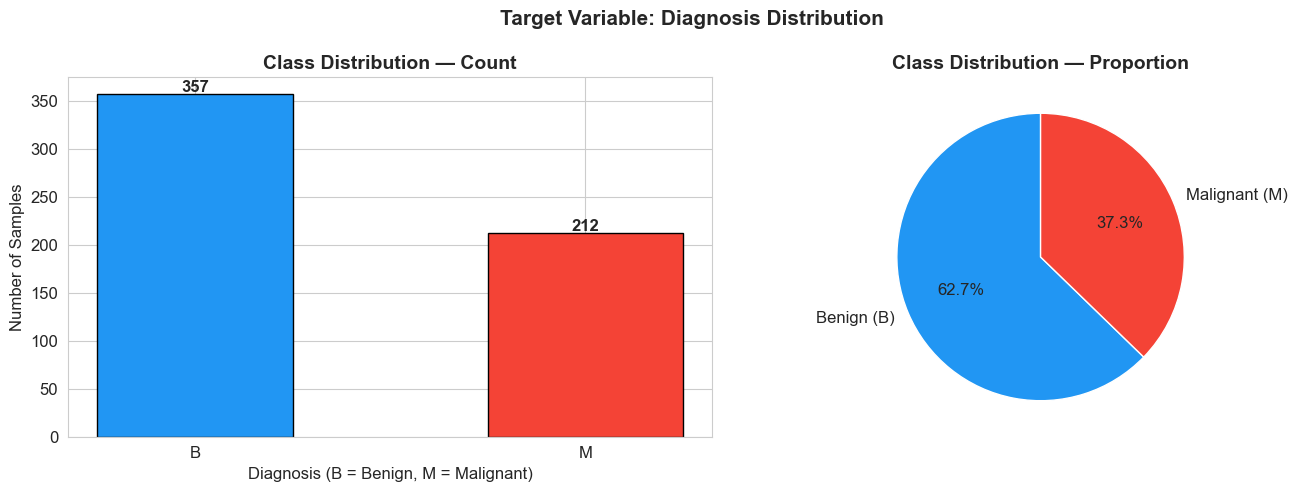

In [11]:
# --- 6.1 Class Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = df['diagnosis'].value_counts()
colors = ['#2196F3', '#F44336']

axes[0].bar(counts.index, counts.values, color=colors, edgecolor='black', width=0.5)
axes[0].set_title('Class Distribution — Count', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Diagnosis (B = Benign, M = Malignant)', fontsize=12)
axes[0].set_ylabel('Number of Samples', fontsize=12)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 3, str(v), ha='center', fontsize=12, fontweight='bold')

axes[1].pie(counts.values, labels=['Benign (B)', 'Malignant (M)'],
            autopct='%1.1f%%', colors=colors, startangle=90,
            textprops={'fontsize': 12})
axes[1].set_title('Class Distribution — Proportion', fontsize=14, fontweight='bold')

plt.suptitle('Target Variable: Diagnosis Distribution', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

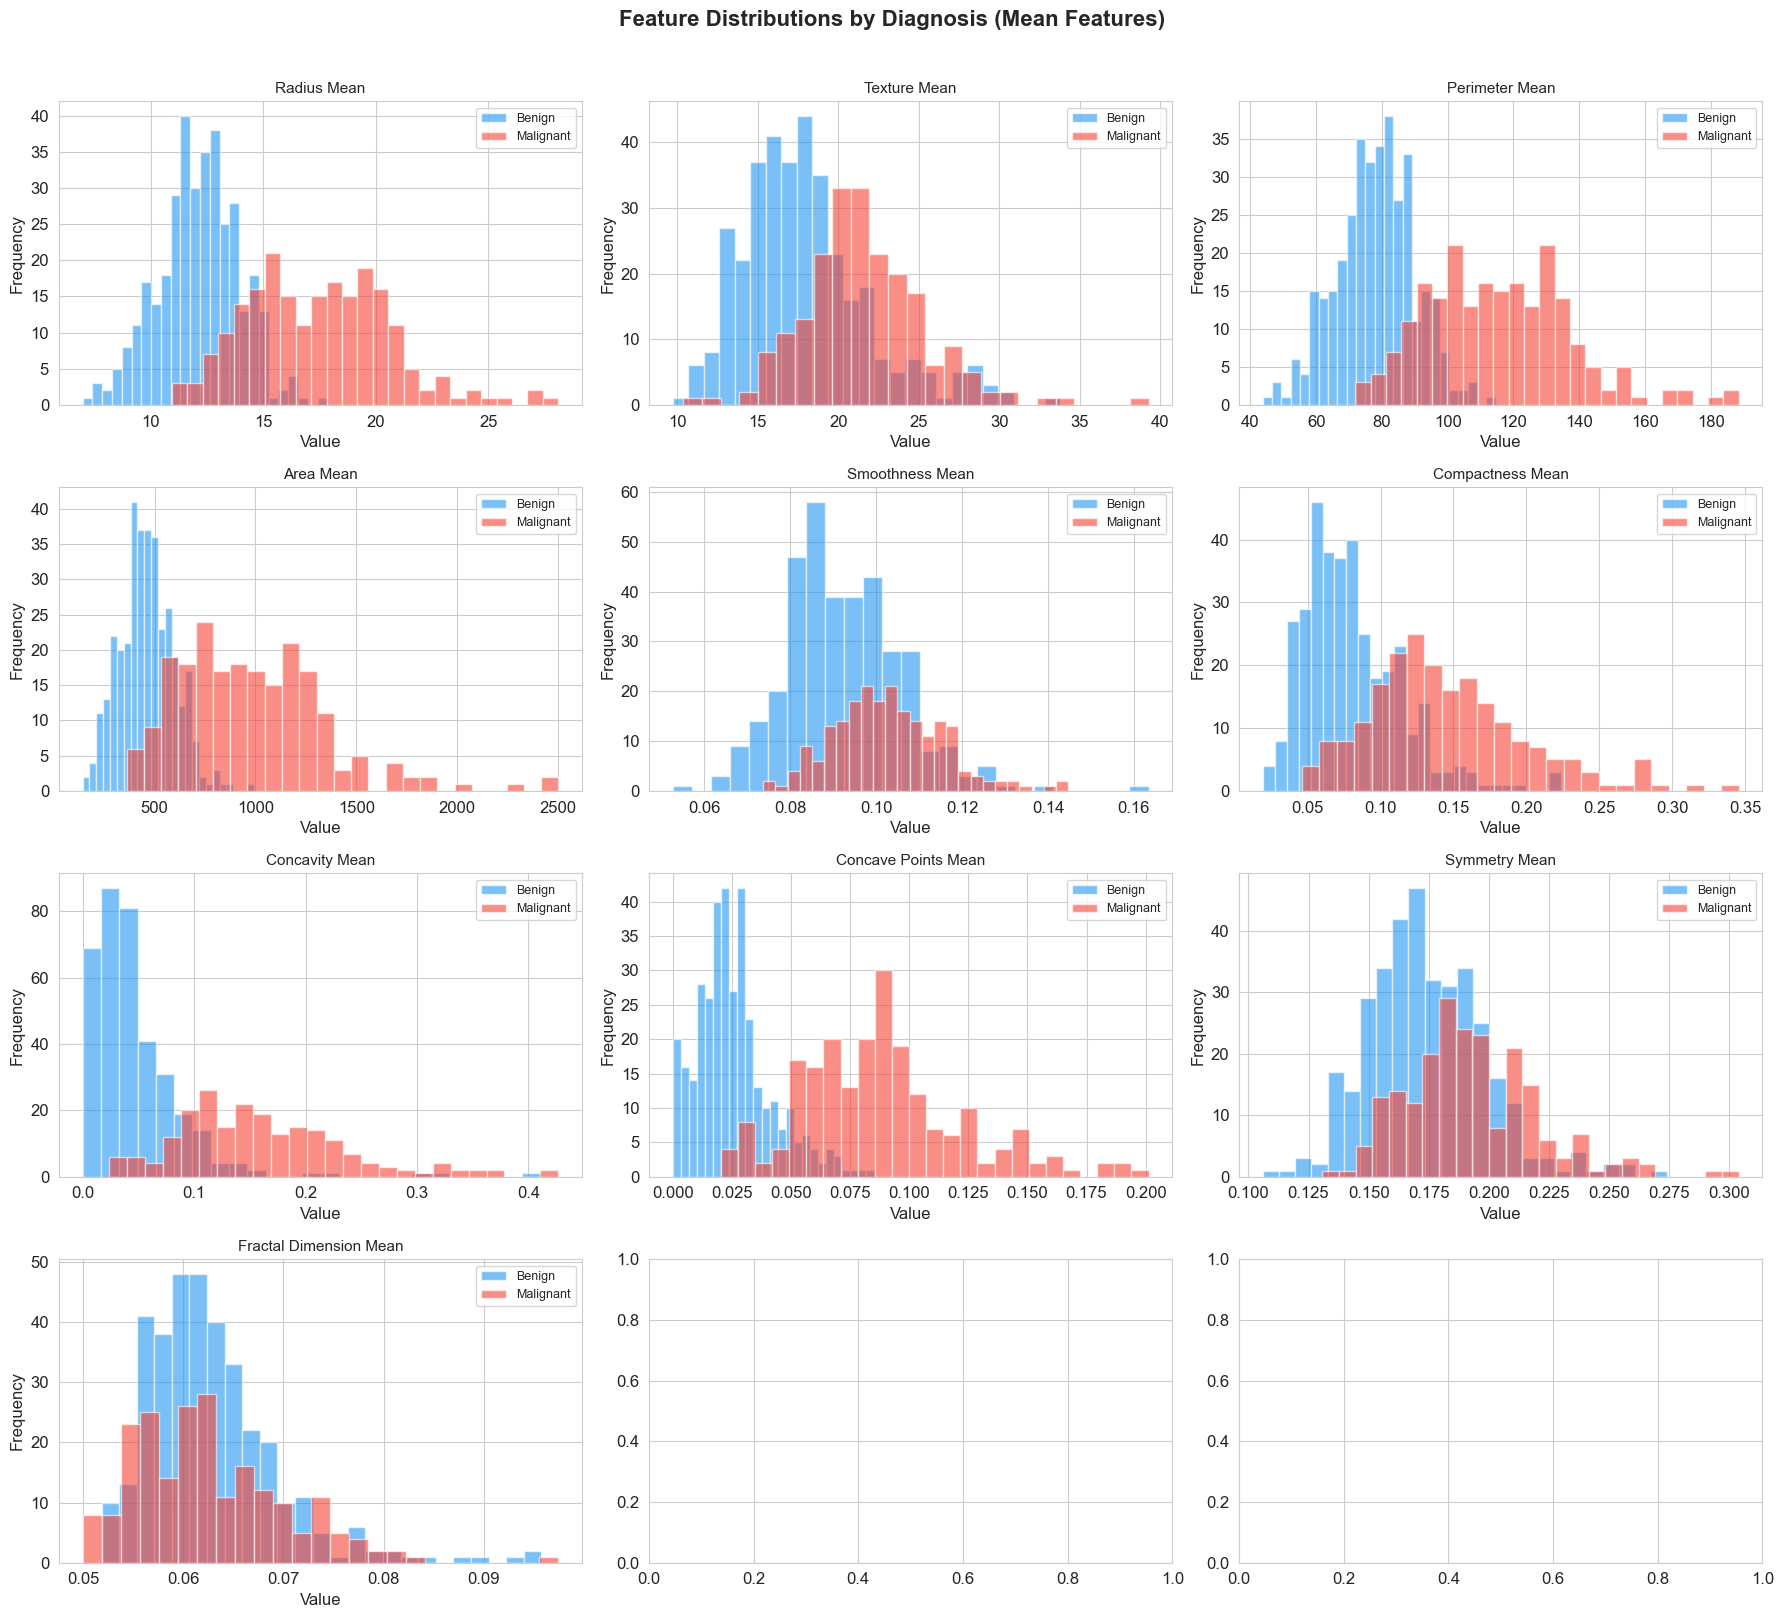

In [12]:
# --- 6.2 Histograms of Mean Features ---
mean_features = [c for c in df.columns if c.endswith('_mean')]

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for i, feat in enumerate(mean_features):
    df[df['diagnosis'] == 'B'][feat].hist(ax=axes[i], bins=25, alpha=0.6,
                                           color='#2196F3', label='Benign')
    df[df['diagnosis'] == 'M'][feat].hist(ax=axes[i], bins=25, alpha=0.6,
                                           color='#F44336', label='Malignant')
    axes[i].set_title(feat.replace('_', ' ').title(), fontsize=11)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=9)

plt.suptitle('Feature Distributions by Diagnosis (Mean Features)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('histograms_mean.png', dpi=150, bbox_inches='tight')
plt.show()

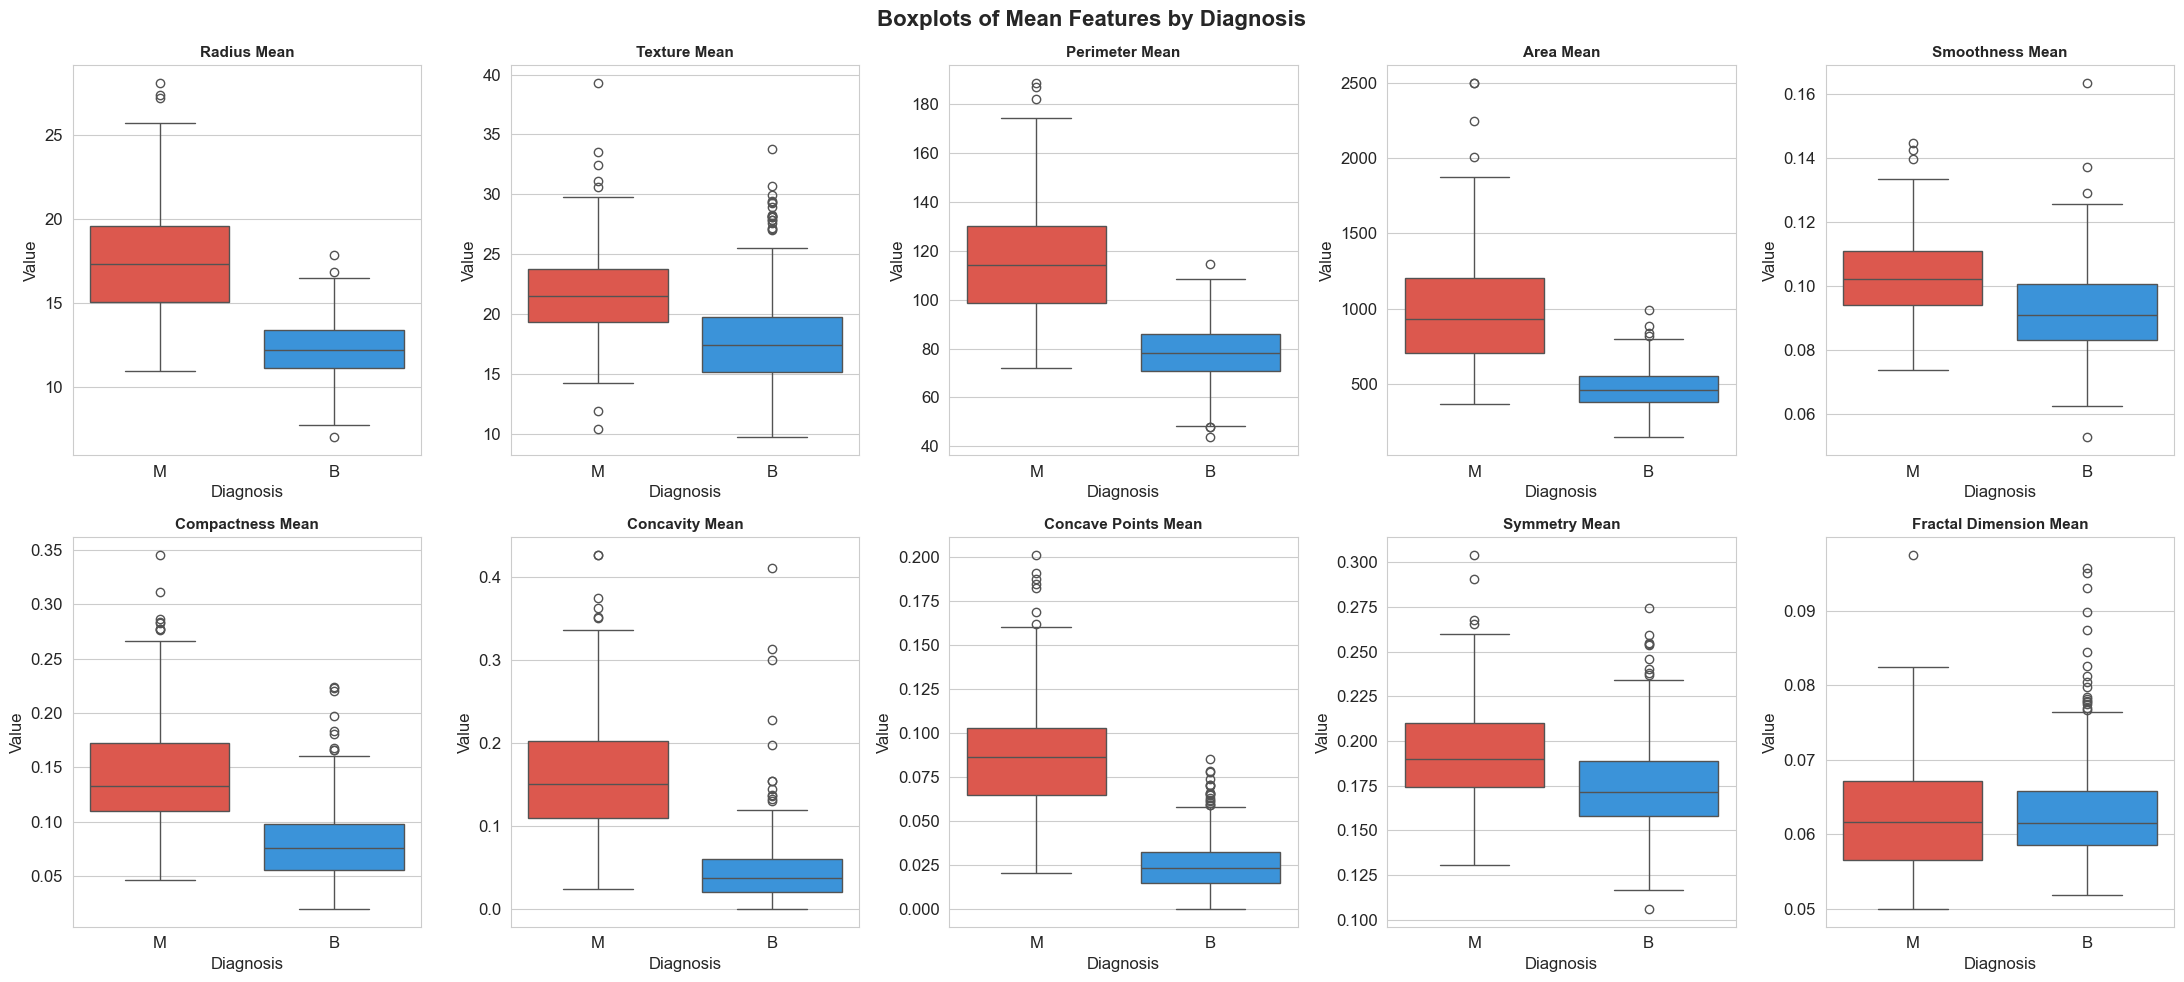

In [13]:
# --- 6.3 Boxplots for Top Mean Features ---
top_features = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
                'smoothness_mean', 'compactness_mean', 'concavity_mean',
                'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean']

fig, axes = plt.subplots(2, 5, figsize=(22, 10))
axes = axes.flatten()

for i, feat in enumerate(top_features):
    sns.boxplot(x='diagnosis', y=feat, data=df, ax=axes[i],
                palette={'B': '#2196F3', 'M': '#F44336'})
    axes[i].set_title(feat.replace('_', ' ').title(), fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Diagnosis')
    axes[i].set_ylabel('Value')

plt.suptitle('Boxplots of Mean Features by Diagnosis',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('boxplots_mean.png', dpi=150, bbox_inches='tight')
plt.show()

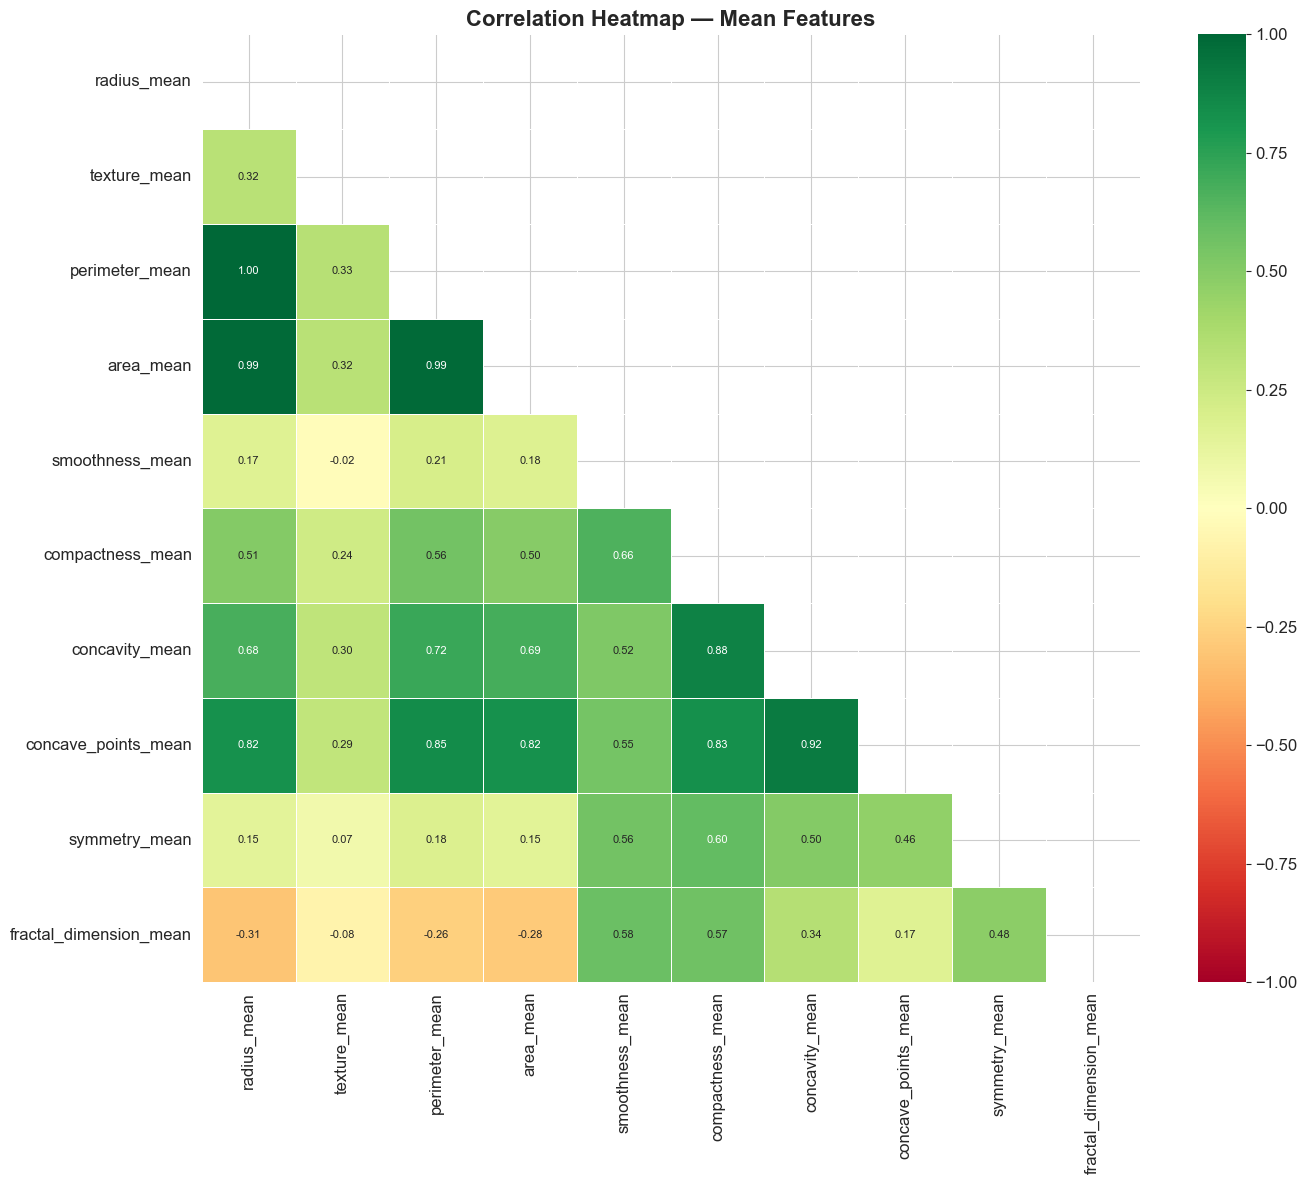

In [14]:
# --- 6.4 Correlation Heatmap (Mean Features) ---
corr_df = df[mean_features].copy()
corr_matrix = corr_df.corr()

plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            mask=mask, linewidths=0.5, vmin=-1, vmax=1,
            annot_kws={'size': 8})
plt.title('Correlation Heatmap — Mean Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

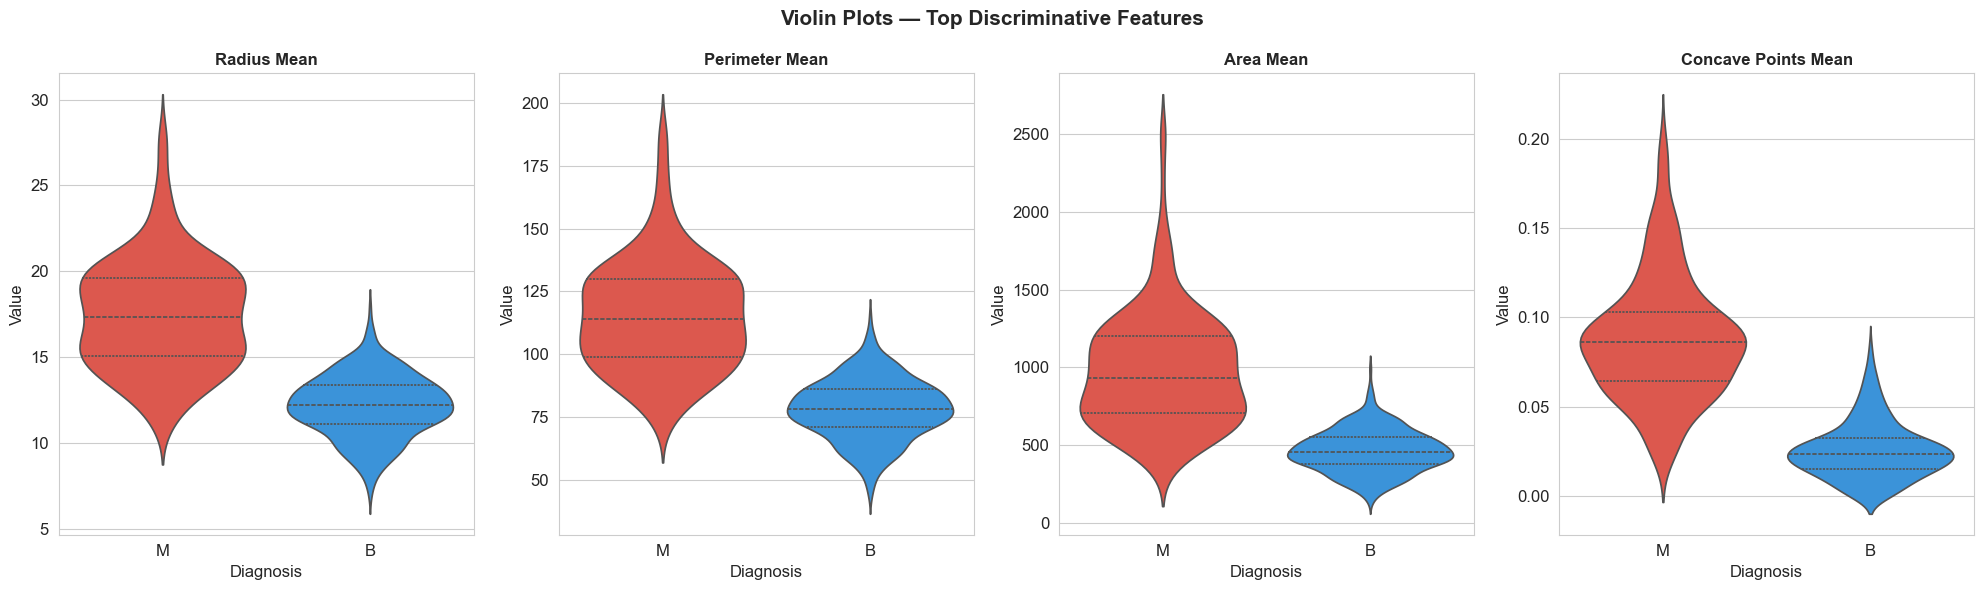

In [15]:
# --- 6.5 Violin Plots for Top Discriminative Features ---
top4 = ['radius_mean', 'perimeter_mean', 'area_mean', 'concave_points_mean']

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
for i, feat in enumerate(top4):
    sns.violinplot(x='diagnosis', y=feat, data=df, ax=axes[i],
                   palette={'B': '#2196F3', 'M': '#F44336'}, inner='quartile')
    axes[i].set_title(feat.replace('_', ' ').title(), fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Diagnosis')
    axes[i].set_ylabel('Value')

plt.suptitle('Violin Plots — Top Discriminative Features', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('violin_plots.png', dpi=150, bbox_inches='tight')
plt.show()

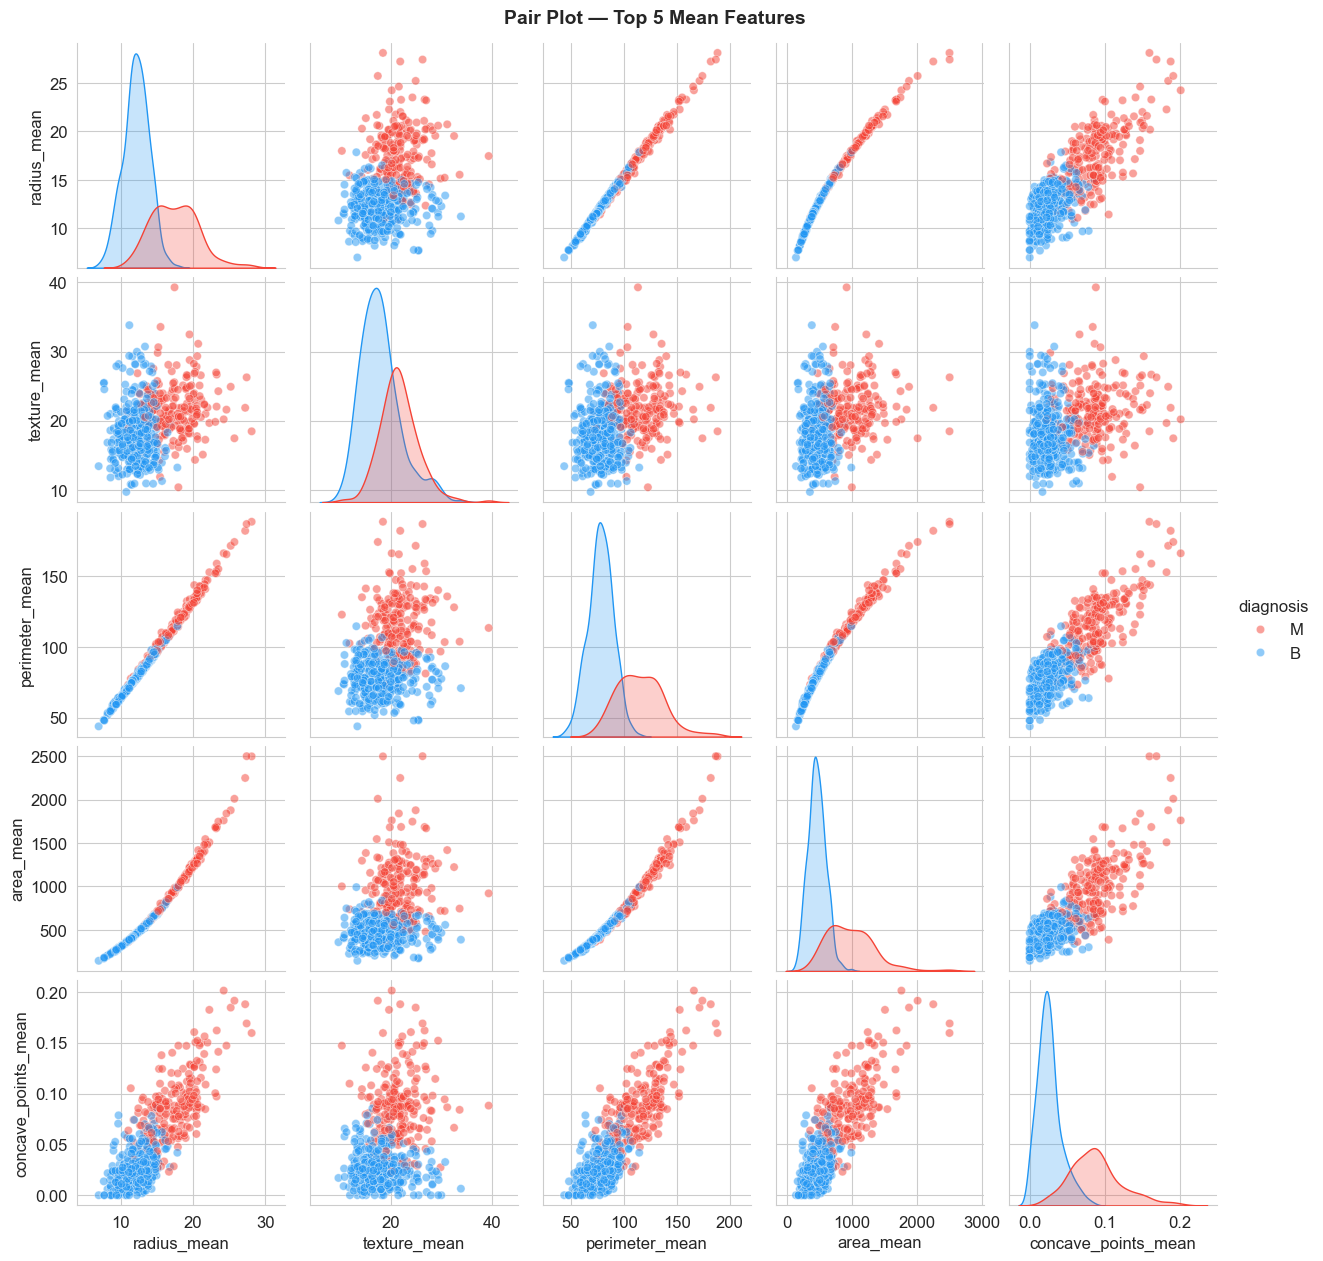

In [16]:
# --- 6.6 Pair Plot of Top 5 Mean Features ---
pair_features = ['radius_mean', 'texture_mean', 'perimeter_mean',
                 'area_mean', 'concave_points_mean', 'diagnosis']

pair_df = df[pair_features].copy()
g = sns.pairplot(pair_df, hue='diagnosis',
                 palette={'B': '#2196F3', 'M': '#F44336'},
                 plot_kws={'alpha': 0.5}, diag_kind='kde')
g.fig.suptitle('Pair Plot — Top 5 Mean Features', y=1.01, fontsize=14, fontweight='bold')
plt.savefig('pairplot.png', dpi=120, bbox_inches='tight')
plt.show()

---
## 7. Data Preprocessing

In [17]:
# Encode target: M=1 (Malignant), B=0 (Benign)
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
print('Target encoding: M → 1 (Malignant), B → 0 (Benign)')
print(df['diagnosis'].value_counts())

Target encoding: M → 1 (Malignant), B → 0 (Benign)
diagnosis
0    357
1    212
Name: count, dtype: int64


In [18]:
# Separate features and target
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

print(f'Feature matrix shape: {X.shape}')
print(f'Target vector shape:  {y.shape}')

Feature matrix shape: (569, 30)
Target vector shape:  (569,)


---
## 8. Train-Test Split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'Training set   : {X_train.shape[0]} samples')
print(f'Test set       : {X_test.shape[0]} samples')
print()
print('Training class distribution:')
print(y_train.value_counts())
print()
print('Test class distribution:')
print(y_test.value_counts())

Training set   : 455 samples
Test set       : 114 samples

Training class distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Test class distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


---
## 9. Feature Scaling

In [20]:
# StandardScaler fitted ONLY on training data to prevent data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('Feature scaling applied (StandardScaler).')
print(f'Training mean (first feature): {X_train_scaled[:, 0].mean():.6f}')
print(f'Training std  (first feature): {X_train_scaled[:, 0].std():.6f}')

Feature scaling applied (StandardScaler).
Training mean (first feature): -0.000000
Training std  (first feature): 1.000000


---
## 10. Model Training

In [21]:
# --- 10.1 Logistic Regression ---
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
print('Logistic Regression trained.')

Logistic Regression trained.


In [22]:
# --- 10.2 Support Vector Machine ---
svm = SVC(probability=True, random_state=42, kernel='rbf')
svm.fit(X_train_scaled, y_train)
print('Support Vector Machine (RBF kernel) trained.')

Support Vector Machine (RBF kernel) trained.


In [23]:
# --- 10.3 Random Forest Classifier ---
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
print('Random Forest Classifier (100 trees) trained.')

Random Forest Classifier (100 trees) trained.


---
## 11. Model Evaluation

In [24]:
def evaluate_model(name, model, X_test, y_test):
    """Returns a dict of evaluation metrics for one model."""
    y_pred      = model.predict(X_test)
    y_prob      = model.predict_proba(X_test)[:, 1]

    acc         = accuracy_score(y_test, y_pred)
    prec        = precision_score(y_test, y_pred)
    rec         = recall_score(y_test, y_pred)
    f1          = f1_score(y_test, y_pred)
    roc         = roc_auc_score(y_test, y_prob)

    print(f'\n{"=" * 55}')
    print(f'  MODEL: {name}')
    print(f'{"=" * 55}')
    print(f'  Accuracy  : {acc:.4f}')
    print(f'  Precision : {prec:.4f}')
    print(f'  Recall    : {rec:.4f}')
    print(f'  F1-Score  : {f1:.4f}')
    print(f'  ROC-AUC   : {roc:.4f}')
    print(f'\nClassification Report:')
    print(classification_report(y_test, y_pred,
                                target_names=['Benign (0)', 'Malignant (1)']))

    return {
        'Model': name, 'Accuracy': acc, 'Precision': prec,
        'Recall': rec, 'F1-Score': f1, 'ROC-AUC': roc,
        'y_pred': y_pred, 'y_prob': y_prob
    }

In [25]:
lr_results  = evaluate_model('Logistic Regression', lr,  X_test_scaled, y_test)
svm_results = evaluate_model('SVM (RBF)',           svm, X_test_scaled, y_test)
rf_results  = evaluate_model('Random Forest',       rf,  X_test_scaled, y_test)


  MODEL: Logistic Regression
  Accuracy  : 0.9649
  Precision : 0.9750
  Recall    : 0.9286
  F1-Score  : 0.9512
  ROC-AUC   : 0.9960

Classification Report:
               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114


  MODEL: SVM (RBF)
  Accuracy  : 0.9737
  Precision : 1.0000
  Recall    : 0.9286
  F1-Score  : 0.9630
  ROC-AUC   : 0.9947

Classification Report:
               precision    recall  f1-score   support

   Benign (0)       0.96      1.00      0.98        72
Malignant (1)       1.00      0.93      0.96        42

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114


  MODEL: Random Forest
  

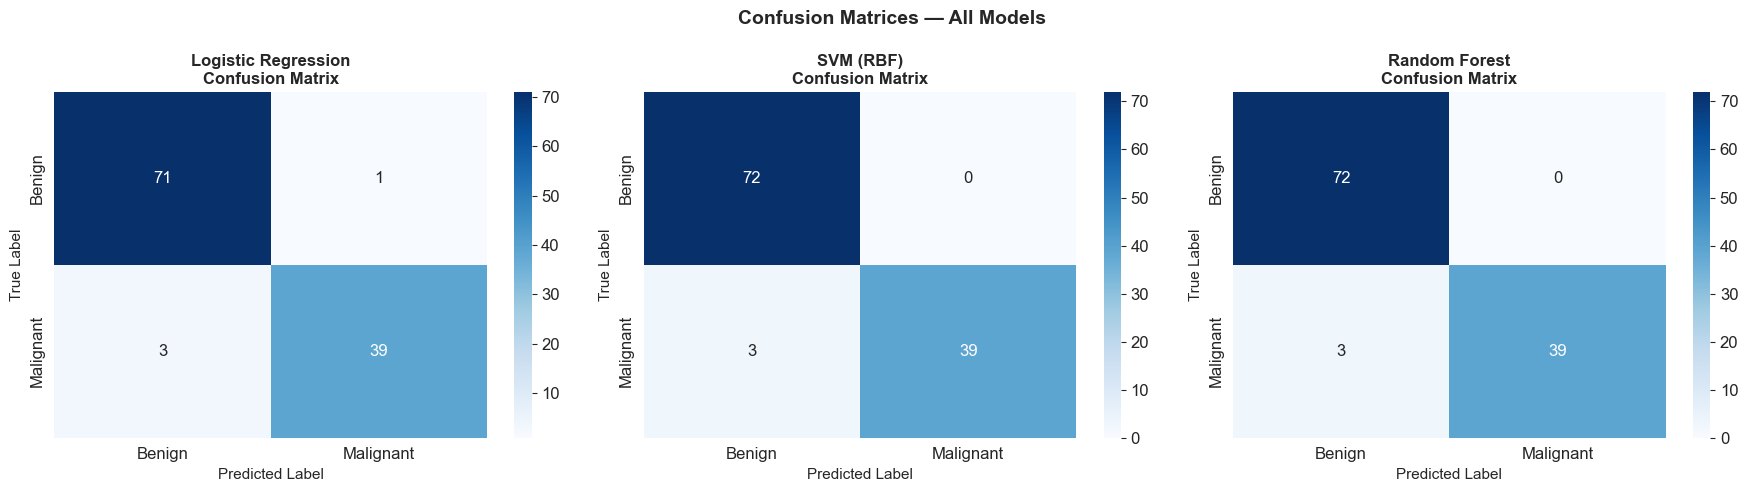

In [26]:
# --- 11.1 Confusion Matrices ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_list = [
    ('Logistic Regression', lr_results['y_pred']),
    ('SVM (RBF)',           svm_results['y_pred']),
    ('Random Forest',      rf_results['y_pred'])
]

for ax, (name, y_pred) in zip(axes, model_list):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'])
    ax.set_title(f'{name}\nConfusion Matrix', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)

plt.suptitle('Confusion Matrices — All Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

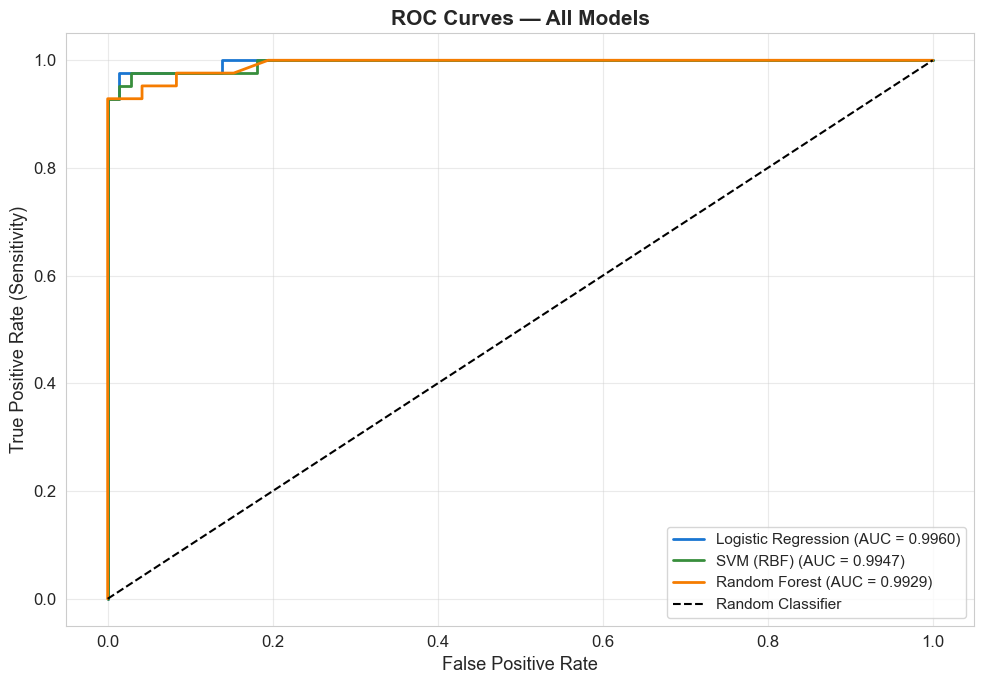

In [27]:
# --- 11.2 ROC Curves ---
plt.figure(figsize=(10, 7))

for res, color in zip(
    [lr_results, svm_results, rf_results],
    ['#1976D2', '#388E3C', '#F57C00']
):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f"{res['Model']} (AUC = {res['ROC-AUC']:.4f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=13)
plt.title('ROC Curves — All Models', fontsize=15, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 12. Model Comparison

In [28]:
# Build comparison table
results_list = [lr_results, svm_results, rf_results]
comparison_df = pd.DataFrame([
    {
        'Model':     r['Model'],
        'Accuracy':  round(r['Accuracy'],  4),
        'Precision': round(r['Precision'], 4),
        'Recall':    round(r['Recall'],    4),
        'F1-Score':  round(r['F1-Score'],  4),
        'ROC-AUC':   round(r['ROC-AUC'],   4)
    }
    for r in results_list
])

comparison_df = comparison_df.sort_values(['Accuracy', 'ROC-AUC'], ascending=False).reset_index(drop=True)
print('=== Model Comparison Table ===')
print(comparison_df.to_string(index=False))

=== Model Comparison Table ===
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
          SVM (RBF)    0.9737      1.000  0.9286    0.9630   0.9947
      Random Forest    0.9737      1.000  0.9286    0.9630   0.9929
Logistic Regression    0.9649      0.975  0.9286    0.9512   0.9960


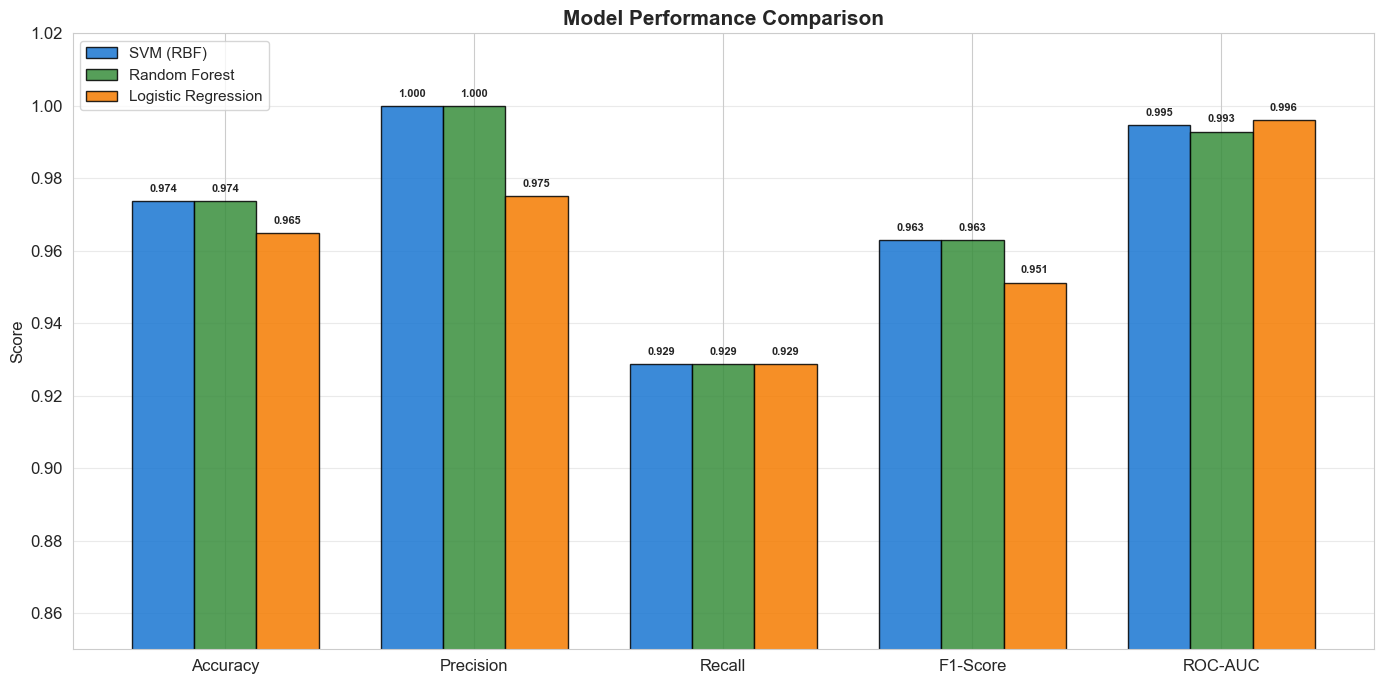

In [29]:
# Bar chart comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
x = np.arange(len(metrics))
width = 0.25
colors = ['#1976D2', '#388E3C', '#F57C00']

fig, ax = plt.subplots(figsize=(14, 7))
for i, (_, row) in enumerate(comparison_df.iterrows()):
    vals = [row[m] for m in metrics]
    bars = ax.bar(x + i * width, vals, width, label=row['Model'],
                  color=colors[i], edgecolor='black', alpha=0.85)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2,
                b.get_height() + 0.002,
                f'{b.get_height():.3f}',
                ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks(x + width)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_ylim(0.85, 1.02)
ax.set_title('Model Performance Comparison', fontsize=15, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 13. Best Model Selection

In [30]:
best_row   = comparison_df.iloc[0]
best_name  = best_row['Model']

print(f'=== Best Model: {best_name} ===')
print(f"  Accuracy  : {best_row['Accuracy']:.4f}")
print(f"  Precision : {best_row['Precision']:.4f}")
print(f"  Recall    : {best_row['Recall']:.4f}")
print(f"  F1-Score  : {best_row['F1-Score']:.4f}")
print(f"  ROC-AUC   : {best_row['ROC-AUC']:.4f}")

print()
print('Medical Context Note:')
print('In a breast cancer screening scenario, RECALL (sensitivity) for')
print('malignant cases is the most critical metric. A false negative')
print('(missing a malignant case) is far more dangerous than a false')
print('positive. The best model should therefore maximize recall for')
print('class 1 (Malignant) while maintaining high overall accuracy.')

=== Best Model: SVM (RBF) ===
  Accuracy  : 0.9737
  Precision : 1.0000
  Recall    : 0.9286
  F1-Score  : 0.9630
  ROC-AUC   : 0.9947

Medical Context Note:
In a breast cancer screening scenario, RECALL (sensitivity) for
malignant cases is the most critical metric. A false negative
(missing a malignant case) is far more dangerous than a false
positive. The best model should therefore maximize recall for
class 1 (Malignant) while maintaining high overall accuracy.


---
## 14. Feature Importance / Interpretation

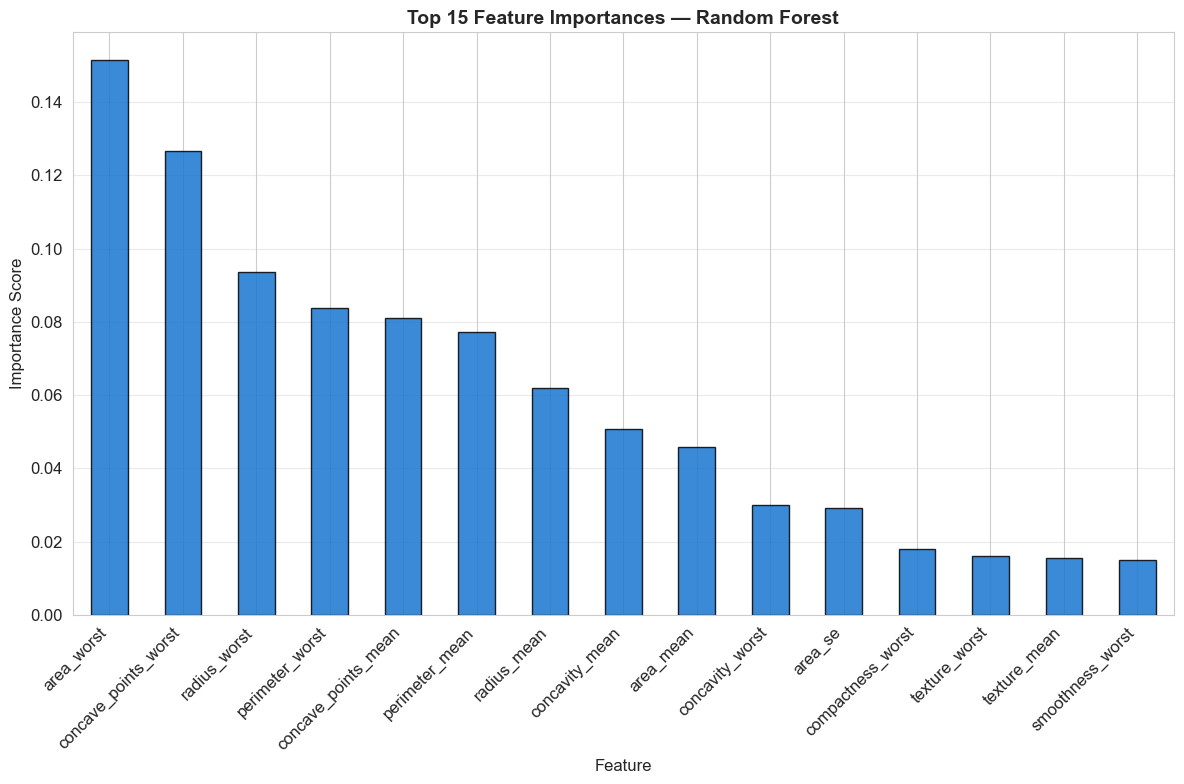

Top 10 most important features:
area_worst              0.151412
concave_points_worst    0.126497
radius_worst            0.093475
perimeter_worst         0.083642
concave_points_mean     0.081082
perimeter_mean          0.077126
radius_mean             0.061990
concavity_mean          0.050818
area_mean               0.045916
concavity_worst         0.030022


In [31]:
# Random Forest Feature Importances
feat_imp = pd.Series(rf.feature_importances_, index=X.columns)
feat_imp = feat_imp.sort_values(ascending=False)

plt.figure(figsize=(12, 8))
feat_imp.head(15).plot(kind='bar', color='#1976D2', edgecolor='black', alpha=0.85)
plt.title('Top 15 Feature Importances — Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Feature', fontsize=12)
plt.ylabel('Importance Score', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 10 most important features:')
print(feat_imp.head(10).to_string())

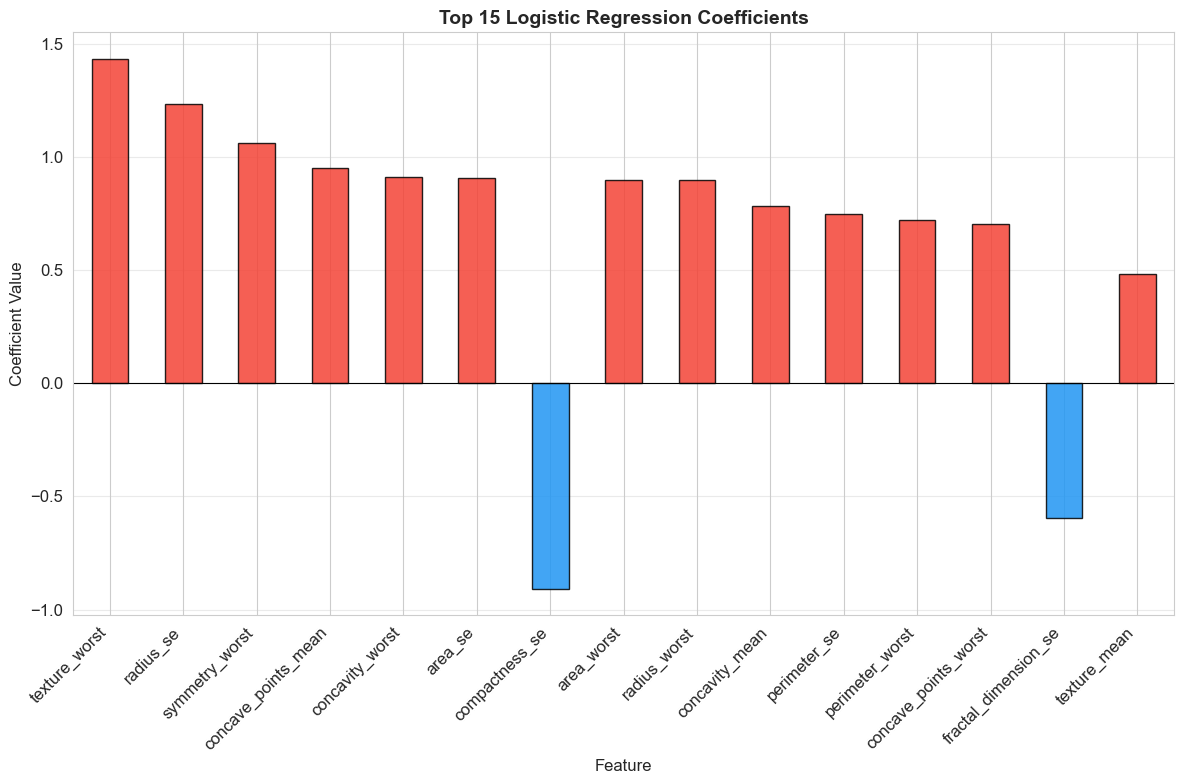

In [32]:
# Logistic Regression Coefficients
coef_series = pd.Series(lr.coef_[0], index=X.columns)
coef_sorted = coef_series.abs().sort_values(ascending=False)

plt.figure(figsize=(12, 8))
coef_series[coef_sorted.index[:15]].plot(
    kind='bar',
    color=['#F44336' if v > 0 else '#2196F3'
           for v in coef_series[coef_sorted.index[:15]]],
    edgecolor='black', alpha=0.85
)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Top 15 Logistic Regression Coefficients', fontsize=14, fontweight='bold')
plt.xlabel('Feature', fontsize=12)
plt.ylabel('Coefficient Value', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('lr_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 15. Conclusion

In [33]:
print('=' * 65)
print('  FINAL SUMMARY — Tanushree_BreastCancerClassification')
print('=' * 65)
print()
print('Dataset    : Breast Cancer Wisconsin (Diagnostic)')
print('Samples    : 569  |  Features : 30')
print('Classes    : Benign (357)  |  Malignant (212)')
print()
print('--- Final Model Scores ---')
print(comparison_df.to_string(index=False))
print()
print(f'Best Model : {best_name}')
print()
print('Key Findings:')
print(' * All three models achieved high accuracy (>95%) on the test set.')
print(' * Recall for malignant cases is the most critical metric in a')
print('   medical screening context — the best model maximizes this.')
print(' * Feature importance analysis shows that worst/mean radius,')
print('   perimeter, area, and concave points are the most predictive.')
print(' * The models are trained on a benchmark dataset and are NOT')
print('   intended to replace professional clinical diagnosis.')
print()
print('Project completed successfully.')

  FINAL SUMMARY — Tanushree_BreastCancerClassification

Dataset    : Breast Cancer Wisconsin (Diagnostic)
Samples    : 569  |  Features : 30
Classes    : Benign (357)  |  Malignant (212)

--- Final Model Scores ---
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
          SVM (RBF)    0.9737      1.000  0.9286    0.9630   0.9947
      Random Forest    0.9737      1.000  0.9286    0.9630   0.9929
Logistic Regression    0.9649      0.975  0.9286    0.9512   0.9960

Best Model : SVM (RBF)

Key Findings:
 * All three models achieved high accuracy (>95%) on the test set.
 * Recall for malignant cases is the most critical metric in a
   medical screening context — the best model maximizes this.
 * Feature importance analysis shows that worst/mean radius,
   perimeter, area, and concave points are the most predictive.
 * The models are trained on a benchmark dataset and are NOT
   intended to replace professional clinical diagnosis.

Project completed successfully.
